# import libraries


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_score
from sklearn.base import clone
import numpy as np
from xgboost import XGBClassifier

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Metrics
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay,
)

# Explainability, tracking, saving
import shap
import mlflow
import joblib

# eda

In [3]:
data = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(data.columns)

data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')

print(data['TotalCharges'].isnull().sum())
print(data['TotalCharges'].isna().sum())

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')
11
11


In [4]:
data.columns
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
data[data['TotalCharges'].isna()][['tenure', 'Churn']]

,tenure,Churn
488,0,No
753,0,No
936,0,No
1082,0,No
1340,0,No
3331,0,No
3826,0,No
4380,0,No
5218,0,No
6670,0,No


In [6]:
data['TotalCharges'] = data['TotalCharges'].fillna(0)
data['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [7]:
churn_map = {'Yes' : 1,
             'No' : 0}

data['Churn_num'] = data['Churn'].map(churn_map)

In [8]:
data[['Churn','Churn_num']]
data['Churn_num'].mean()

np.float64(0.2653698707936959)

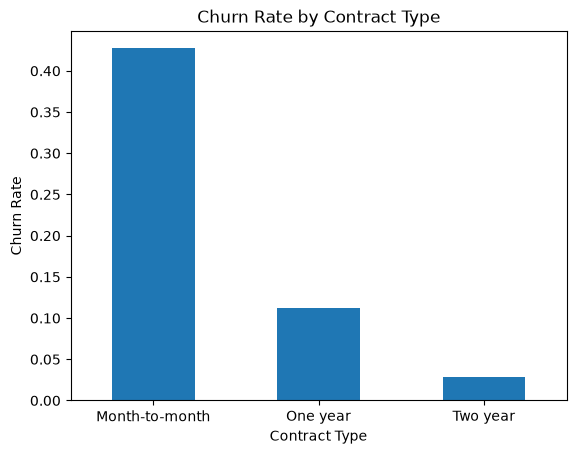

In [9]:
data.groupby('Contract')['Churn_num'].mean().plot(kind='bar')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Contract Type')
plt.xticks(rotation=0)
plt.savefig('../reports/figures/churn_by_contract.png', dpi=150, bbox_inches='tight')
plt.show()

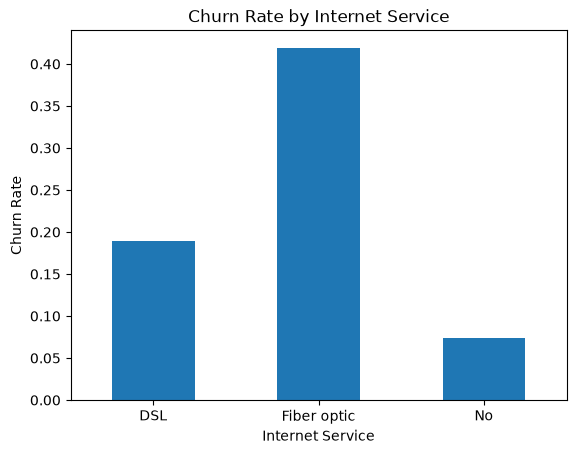

In [10]:
data.groupby('InternetService')['Churn_num'].mean().plot(kind='bar')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Internet Service')
plt.xticks(rotation=0)
plt.savefig('../reports/figures/churn_by_internet_service.png', dpi=150, bbox_inches='tight')
plt.show()

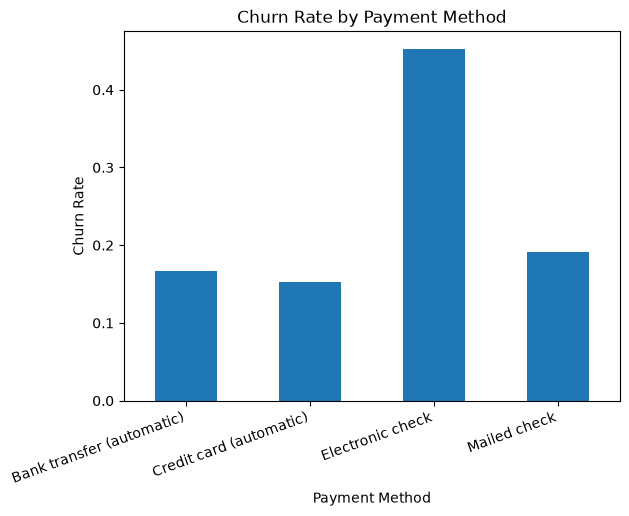

In [11]:
data.groupby('PaymentMethod')['Churn_num'].mean().plot(kind='bar')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Payment Method')
plt.xticks(rotation=20, ha='right')
plt.savefig('../reports/figures/churn_by_payment_method.png', dpi=150, bbox_inches='tight')
plt.show()


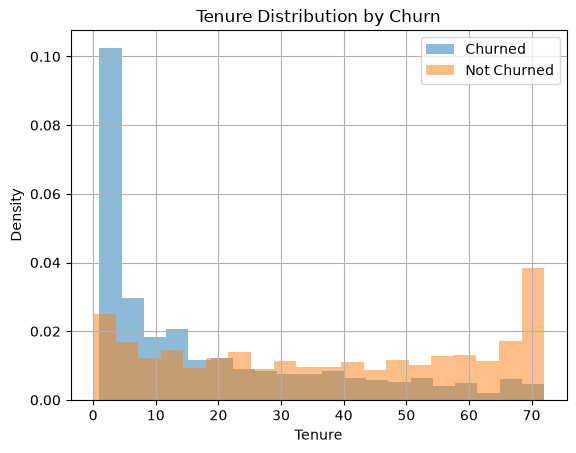

In [12]:
data[data['Churn'] == 'Yes']['tenure'].hist(
    alpha=0.5, label='Churned', bins=20, density = True
)

data[data['Churn'] == 'No']['tenure'].hist(
    alpha=0.5, label='Not Churned', bins=20, density = True
)

plt.xlabel('Tenure')
plt.ylabel('Density')
plt.title('Tenure Distribution by Churn')
plt.legend()
plt.savefig('../reports/figures/tenure_distribution_by_churn.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
data.groupby('Churn')['tenure'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


In [14]:
data.groupby('Churn')['MonthlyCharges'].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

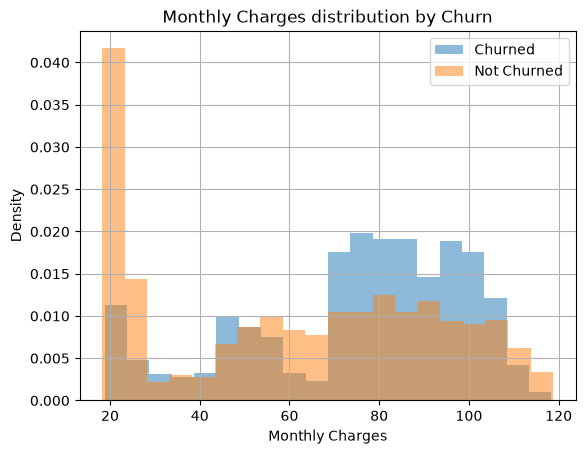

In [15]:
data[data['Churn'] == 'Yes' ]['MonthlyCharges'].hist(
    alpha = 0.5, label = 'Churned', bins= 20, density=True
)

data[data['Churn'] == 'No' ]['MonthlyCharges'].hist(
    alpha = 0.5, label = 'Not Churned', bins= 20, density=True
)

plt.xlabel('Monthly Charges')
plt.ylabel('Density')
plt.title('Monthly Charges distribution by Churn')
plt.legend()
plt.savefig('../reports/figures/monthly_charges_by_churn.png', dpi=150, bbox_inches='tight')
plt.show()

# Preprocessing

In [16]:
x = data.drop(['customerID', 'Churn', 'Churn_num'], axis=1)
y = data['Churn_num']

x.shape
y.shape

(7043,)

In [17]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1, stratify=y )

In [18]:
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
non_numeric = x.select_dtypes(include=[
    'object', 'string'
])
non_numeric_cols = non_numeric.columns.to_list()

transformer = ColumnTransformer(transformers=[
('categorical', OneHotEncoder( handle_unknown='ignore', sparse_output= False), non_numeric_cols),
('numeric', StandardScaler(), numeric_cols)
], remainder= 'passthrough' )

In [19]:
base_model = DummyClassifier(strategy= 'most_frequent')
logistic_model = LogisticRegression(max_iter=1000)
forest_model = RandomForestClassifier(n_estimators=200, random_state=1)
xgboost_model = XGBClassifier(n_estimators = 300,
                        learning_rate = 0.05,
                        max_depth = 3,
                        eval_metric = 'logloss',
                        random_state = 1)

base_pipeline = Pipeline(steps=[
    ('transformer', clone(transformer)),
    ('model', base_model)
])

logistic_pipeline = Pipeline(steps=[
    ('transformer', clone(transformer)),
    ('model', logistic_model)
])

forest_pipeline = Pipeline(steps=[
    ('transformer', clone(transformer)),
    ('model', forest_model)
])

xgboost_pipeline = Pipeline(steps=[
    ('transformer', clone(transformer)),
    ('model', xgboost_model)
])

In [20]:
my_pipelines = {
    'baseline': base_pipeline,
    'logistic': logistic_pipeline,
    'forest': forest_pipeline,
    'xgboost': xgboost_pipeline
}

cv = StratifiedKFold(n_splits= 5, shuffle= True, random_state= 1)

results = {}
for name,pipeline in my_pipelines.items():
    output = cross_validate(
        pipeline,x_train,y_train,
        cv=cv,
        scoring=['roc_auc', 'precision', 'recall', 'f1']
    )
    results[name] = {
        metric: values.mean()
        for metric, values in output.items()
    }
results_df = pd.DataFrame(results).T
results_df


/home/huseyn/Desktop/churn_model/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/huseyn/Desktop/churn_model/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/huseyn/Desktop/churn_model/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()}

,fit_time,score_time,test_roc_auc,test_precision,test_recall,test_f1
baseline,0.057281,0.055517,0.500000,0.000000,0.000000,0.000000
logistic,0.078324,0.064145,0.846719,0.650480,0.545819,0.592999
forest,0.979031,0.150134,0.828738,0.631695,0.476923,0.542529
xgboost,0.221823,0.068756,0.845645,0.653433,0.525753,0.582319


# adding mlflow

In [22]:
mlflow.set_tracking_uri('sqlite:///../mlflow.db')
mlflow.set_experiment('churn-prediction')

for name, scores in results.items():
    with mlflow.start_run(run_name=name):
        mlflow.log_param('model_name',name)
        for metric_name, value in scores.items():
            mlflow.log_metric(metric_name, value)   

2026/11/28 20:24:11 INFO mlflow.tracking.fluent: Experiment with name 'churn-prediction' does not exist. Creating a new experiment.
